# Análisis Exploratorio de Datos y Preprocesamiento
## Dataset: San Francisco City Employee Salaries

**Curso:** Aprendizaje Automático — MIAR0525  
**Objetivo:** Demostrar todas las etapas del preprocesamiento de datos previas a la construcción de un modelo de Machine Learning.

---
### Descripción del Dataset
Este dataset contiene información sobre los salarios de empleados públicos de la ciudad de San Francisco (EE.UU.) entre los años 2011 y 2014. Incluye variables como el nombre del empleado, título del puesto, salario base, horas extra, beneficios y compensación total.

**Fuente:** [SF Salaries — Kaggle](https://www.kaggle.com/datasets/kaggle/sf-salaries)  
**Registros:** ~148,654  
**Variables:** 13

---
### Flujo de trabajo
```
Carga → Inspección → EDA → Valores faltantes → Outliers → Limpieza → Ingeniería de características → Codificación → Escalado → Dataset final
```

---
## 0. (PRY)Importación de librerías

In [1]:
#from google.colab import drive
#drive.mount('/content/drive')

In [2]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Preprocesamiento (scikit-learn)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Configuración general
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

import warnings
warnings.filterwarnings('ignore')

print(' Librerías importadas correctamente.')

 Librerías importadas correctamente.


---
## 1. (PRY)Carga del Dataset

In [12]:
# Cargamos el dataset
# low_memory=False evita advertencias de tipos mixtos al leer columnas con valores heterogéneos
df = pd.read_csv(r'C:\Users\PAULA\Documents\IntegradorG3\data\raw\data_proyecto\data_proyecto.csv', low_memory=False)

print(f'Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas')

Dataset cargado: 17,680,253 filas × 11 columnas


**1.1 (PRY)Consolidación de los archivos de Data**

In [13]:
#import os
#import glob
#import pandas as pd
#
## Definir rutas de origen y destino
#path_origen = '/content/drive/MyDrive/Proyecto/data/raw'
#archivo_salida = '/content/drive/MyDrive/Proyecto/data/data_proyecto.csv'
#
## Asegurar que el directorio de destino exista
#destino_dir = os.path.dirname(archivo_salida)
#if not os.path.exists(destino_dir):
#    os.makedirs(destino_dir, exist_ok=True)
#
## Buscar archivos que coincidan con ambos patrones de nombres estructurados
#patron_incidentes = os.path.join(path_origen, 'incidentes_*.csv')
#patron_emergencias = os.path.join(path_origen, 'emergencias_*.csv')
#
#archivos = glob.glob(patron_incidentes) + glob.glob(patron_emergencias)
#
## Filtrar para evitar incluir el archivo de salida si coincide con los patrones
#archivos = [f for f in archivos if os.path.basename(f) != 'data_proyecto.csv' and os.path.isfile(f)]
#
#if not archivos:
#    print(f'No se encontraron archivos "incidentes_*.csv" o "emergencias_*.csv" en la ruta: {path_origen}')
#else:
#    print(f'Se encontraron {len(archivos)} archivos válidos para consolidar.')
#
#    # Leer y concatenar los archivos manteniendo consistencia de tipos de datos
#    lista_dataframes = []
#    for i, archivo in enumerate(archivos):
#        df_temp = None
#        ultimo_error = ""
#
#        # Probamos combinaciones explícitas de separador y codificación para máxima robustez
#        for separador in [',', ';']:
#            if df_temp is not None:
#                break
#            for encoding in ['utf-8', 'latin-1', 'utf-8-sig']:
#                try:
#                    df_temp = pd.read_csv(archivo, sep=separador, encoding=encoding, low_memory=False)
#                    # Si se leyó pero con una sola columna mal estructurada, seguimos buscando un mejor separador
#                    if df_temp.shape[1] <= 1 and separador == ',':
#                        # Podría ser que el separador real sea ';' y por eso leyó todo en una sola columna
#                        df_temp = None
#                        continue
#                    break
#                except Exception as e:
#                    ultimo_error = str(e)
#                    df_temp = None
#
#        if df_temp is not None:
#            lista_dataframes.append(df_temp)
#            print(f'[{i+1}/{len(archivos)}] Procesado exitosamente: {os.path.basename(archivo)} (Columnas: {df_temp.shape[1]})')
#        else:
#            print(f'[{i+1}/{len(archivos)}] ERROR en {os.path.basename(archivo)}: {ultimo_error}')
#
#    if lista_dataframes:
#        # Concatenar todos los dataframes de la lista
#        df_consolidado = pd.concat(lista_dataframes, ignore_index=True)
#
#        # Guardar en un único archivo CSV. header=True guardará la cabecera únicamente una vez al inicio.
#        df_consolidado.to_csv(archivo_salida, index=False, header=True, encoding='utf-8')
#        print(f'\nConsolidación completada con éxito. Archivo guardado en: {archivo_salida}')
#        print(f'Dimensiones finales del dataset consolidado: {df_consolidado.shape[0]:,} filas × {df_consolidado.shape[1]} columnas')
#    else:
#        print('No se pudo procesar ningún archivo de manera exitosa.')

---
## 2. (PRY)Inspección Inicial
El primer paso siempre es entender **qué tenemos**: cuántas filas, qué columnas, qué tipos de datos y cómo luce la información.

In [14]:
# Primeras 5 filas
print('=== Primeras 5 filas ===')
df.head()

=== Primeras 5 filas ===


,Fecha,provincia,Canton,Cod_Parroquia,Parroquia,Servicio,Subtipo,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,1/8/2025,NAPO,ARCHIDONA,150350.00,"ARCHIDONA, CABECERA CANTONAL",Servicio Militar,Seguridad exterior a C.P.L.,NaN,NaN,NaN,NaN
1,1/8/2025,PICHINCHA,QUITO,170155.00,CALDERÓN (CARAPUNGO),Seguridad Ciudadana,Apoyo a instituciones articuladas,NaN,NaN,NaN,NaN
2,1/8/2025,PICHINCHA,QUITO,170152.00,AMAGUAÑA,Gestión Sanitaria,Consulta médica,NaN,NaN,NaN,NaN
3,1/8/2025,PICHINCHA,QUITO,170150.00,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Tránsito y Movilidad,Otros,NaN,NaN,NaN,NaN
4,1/8/2025,PICHINCHA,QUITO,170175.00,PIFO,Seguridad Ciudadana,Presencia policial,NaN,NaN,NaN,NaN


In [15]:
# Últimas 5 filas
print('=== Últimas 5 filas ===')
df.tail()

=== Últimas 5 filas ===


,Fecha,provincia,Canton,Cod_Parroquia,Parroquia,Servicio,Subtipo,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
17680248,30/9/2022,GUAYAS,GUAYAQUIL,90150.00,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",Seguridad Ciudadana,Patrullaje policial en el sector solicitado,NaN,NaN,NaN,NaN
17680249,30/9/2022,GUAYAS,GUAYAQUIL,90150.00,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",Seguridad Ciudadana,Escándalo en espacio público,NaN,NaN,NaN,NaN
17680250,30/9/2022,GUAYAS,GUAYAQUIL,90150.00,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",Seguridad Ciudadana,Agresión verbal,NaN,NaN,NaN,NaN
17680251,30/9/2022,GUAYAS,GUAYAQUIL,90150.00,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",Seguridad Ciudadana,Custodia policial en lugares de riesgo temporal,NaN,NaN,NaN,NaN
17680252,30/9/2022,GUAYAS,GUAYAQUIL,90150.00,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",Seguridad Ciudadana,Patrullaje policial en el sector solicitado,NaN,NaN,NaN,NaN


In [16]:
# Información estructural del DataFrame
# Muestra: tipo de dato por columna, valores no nulos y uso de memoria
print('=== Información estructural ===')
df.info()

=== Información estructural ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17680253 entries, 0 to 17680252
Data columns (total 11 columns):
 #   Column         Dtype  
---  ------         -----  
 0   Fecha          object 
 1   provincia      object 
 2   Canton         object 
 3   Cod_Parroquia  float64
 4   Parroquia      object 
 5   Servicio       object 
 6   Subtipo        object 
 7   Unnamed: 7     object 
 8   Unnamed: 8     float64
 9   Unnamed: 9     float64
 10  Unnamed: 10    object 
dtypes: float64(3), object(8)
memory usage: 1.4+ GB


In [17]:
# Dimensiones
print(f'Filas    : {df.shape[0]:,}')
print(f'Columnas : {df.shape[1]}')
print(f'Celdas   : {df.shape[0] * df.shape[1]:,}')

Filas    : 17,680,253
Columnas : 11
Celdas   : 194,482,783


In [18]:
# Tipos de datos por columna
print('=== Tipos de datos ===')
print(df.dtypes)

=== Tipos de datos ===
Fecha             object
provincia         object
Canton            object
Cod_Parroquia    float64
Parroquia         object
Servicio          object
Subtipo           object
Unnamed: 7        object
Unnamed: 8       float64
Unnamed: 9       float64
Unnamed: 10       object
dtype: object


**Cambio de tipo de dato**

In [19]:
# 1. Identificar todas las columnas excepto 'Fecha' para convertirlas a string
columnas_string = [col for col in df.columns if col.lower() != 'fecha']
df[columnas_string] = df[columnas_string].astype(str)

# 2. Convertir la columna 'Fecha' a tipo datetime especificando el formato día/mes/año
# format='%d/%m/%Y' representa el estándar de día/mes/año de cuatro dígitos (d/m/aaaa)
df['Fecha'] = pd.to_datetime(df['Fecha'], format='%d/%m/%Y', errors='coerce')

# Mostrar los nuevos tipos de datos de las columnas
print('=== Nuevos tipos de datos del DataFrame ===')
print(df.dtypes)

=== Nuevos tipos de datos del DataFrame ===
Fecha            datetime64[ns]
provincia                object
Canton                   object
Cod_Parroquia            object
Parroquia                object
Servicio                 object
Subtipo                  object
Unnamed: 7               object
Unnamed: 8               object
Unnamed: 9               object
Unnamed: 10              object
dtype: object


In [20]:
# Mostrar las primeras 10 filas para verificar los cambios de formato
display(df.head(10))

,Fecha,provincia,Canton,Cod_Parroquia,Parroquia,Servicio,Subtipo,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,2025-08-01,NAPO,ARCHIDONA,150350.0,"ARCHIDONA, CABECERA CANTONAL",Servicio Militar,Seguridad exterior a C.P.L.,nan,nan,nan,nan
1,2025-08-01,PICHINCHA,QUITO,170155.0,CALDERÓN (CARAPUNGO),Seguridad Ciudadana,Apoyo a instituciones articuladas,nan,nan,nan,nan
2,2025-08-01,PICHINCHA,QUITO,170152.0,AMAGUAÑA,Gestión Sanitaria,Consulta médica,nan,nan,nan,nan
3,2025-08-01,PICHINCHA,QUITO,170150.0,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Tránsito y Movilidad,Otros,nan,nan,nan,nan
4,2025-08-01,PICHINCHA,QUITO,170175.0,PIFO,Seguridad Ciudadana,Presencia policial,nan,nan,nan,nan
5,2025-08-01,ORELLANA,ORELLANA,220150.0,"PUERTO FRANCISCO DE ORELLANA (EL COCA),CABECER...",Seguridad Ciudadana,Ficha de datos,nan,nan,nan,nan
6,2025-08-01,PICHINCHA,QUITO,170150.0,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Tránsito y Movilidad,Choque lateral angular,nan,nan,nan,nan
7,2025-08-01,PICHINCHA,QUITO,170150.0,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Seguridad Ciudadana,Ficha de datos,nan,nan,nan,nan
8,2025-08-01,PICHINCHA,QUITO,170150.0,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Seguridad Ciudadana,Ficha de datos,nan,nan,nan,nan
9,2025-08-01,PICHINCHA,QUITO,170150.0,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",Seguridad Ciudadana,Ficha de datos,nan,nan,nan,nan


In [21]:
# NO (PRY)
# ¿Hay filas duplicadas?
# df.duplicated() por defecto considera la tupla o renglón completo (todas las columnas) para identificar duplicados
#duplicados = df.duplicated().sum()
#print(f'Filas duplicadas totales (considerando el renglón completo): {duplicados}')

---
## 3. Análisis Exploratorio de Datos (EDA)
El EDA nos permite **entender la distribución, relaciones y calidad** de los datos antes de cualquier modelado.

### 3.1 NO (PRY) Estadísticas Descriptivas

In [22]:
# Estadísticas descriptivas de variables numéricas
# Incluye: conteo, media, desviación estándar, mín, cuartiles, máx
#df.describe(include='all')

In [23]:
# Estadísticas descriptivas de variables categóricas
df.describe(include='object')

,provincia,Canton,Cod_Parroquia,Parroquia,Servicio,Subtipo,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
count,17680253,17680253,17680253,17680253,17680253,17680253,17680253,17680253,17680253,17680253
unique,27,225,1043,981,8,694,2,1,1,2
top,PICHINCHA,QUITO,90150.0,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",Seguridad Ciudadana,Patrullaje policial en el sector solicitado,nan,nan,nan,nan
freq,4351953,3858572,3015047,3015013,12268977,4354616,17680252,17680253,17680253,17680252


In [24]:
# Valores únicos por columna (útil para detectar variables de alta cardinalidad)
print('=== Valores únicos por columna ===')
for col in df.columns:
    n = df[col].nunique()
    print(f'  {col:<20}: {n:>7,} valores únicos')

=== Valores únicos por columna ===
  Fecha               :   1,888 valores únicos
  provincia           :      27 valores únicos
  Canton              :     225 valores únicos
  Cod_Parroquia       :   1,043 valores únicos
  Parroquia           :     981 valores únicos
  Servicio            :       8 valores únicos
  Subtipo             :     694 valores únicos
  Unnamed: 7          :       2 valores únicos
  Unnamed: 8          :       1 valores únicos
  Unnamed: 9          :       1 valores únicos
  Unnamed: 10         :       2 valores únicos


### 3.3 (PRY) Análisis de Variables Categóricas

=== Distribución de la columna Servicio ===


,Frecuencia,Porcentaje (%)
Servicio,,
Seguridad Ciudadana,12268977,69.39
Gestión Sanitaria,2073797,11.73
Tránsito y Movilidad,1879422,10.63
Servicios Municipales,851552,4.82
Gestión de Siniestros,305453,1.73
Servicio Militar,210828,1.19
Gestión de Riesgos,88003,0.50
nan,2221,0.01



=== Top 20 Subtipos más frecuentes ===


,Frecuencia,Porcentaje (%)
Subtipo,,
Patrullaje policial en el sector solicitado,4354616,24.63
Libadores,1332668,7.54
Presencia policial,941924,5.33
Resguardo a personas que traslada valores a nivel local,569908,3.22
Escándalo en espacio público,550735,3.11
Procedimientos,406976,2.30
Registro de personas y/o vehículos con actitud sospechosa,338485,1.91
Ficha de datos información,308604,1.75
Violencia contra la mujer o miembros del núcleo familiar psicológica,274704,1.55


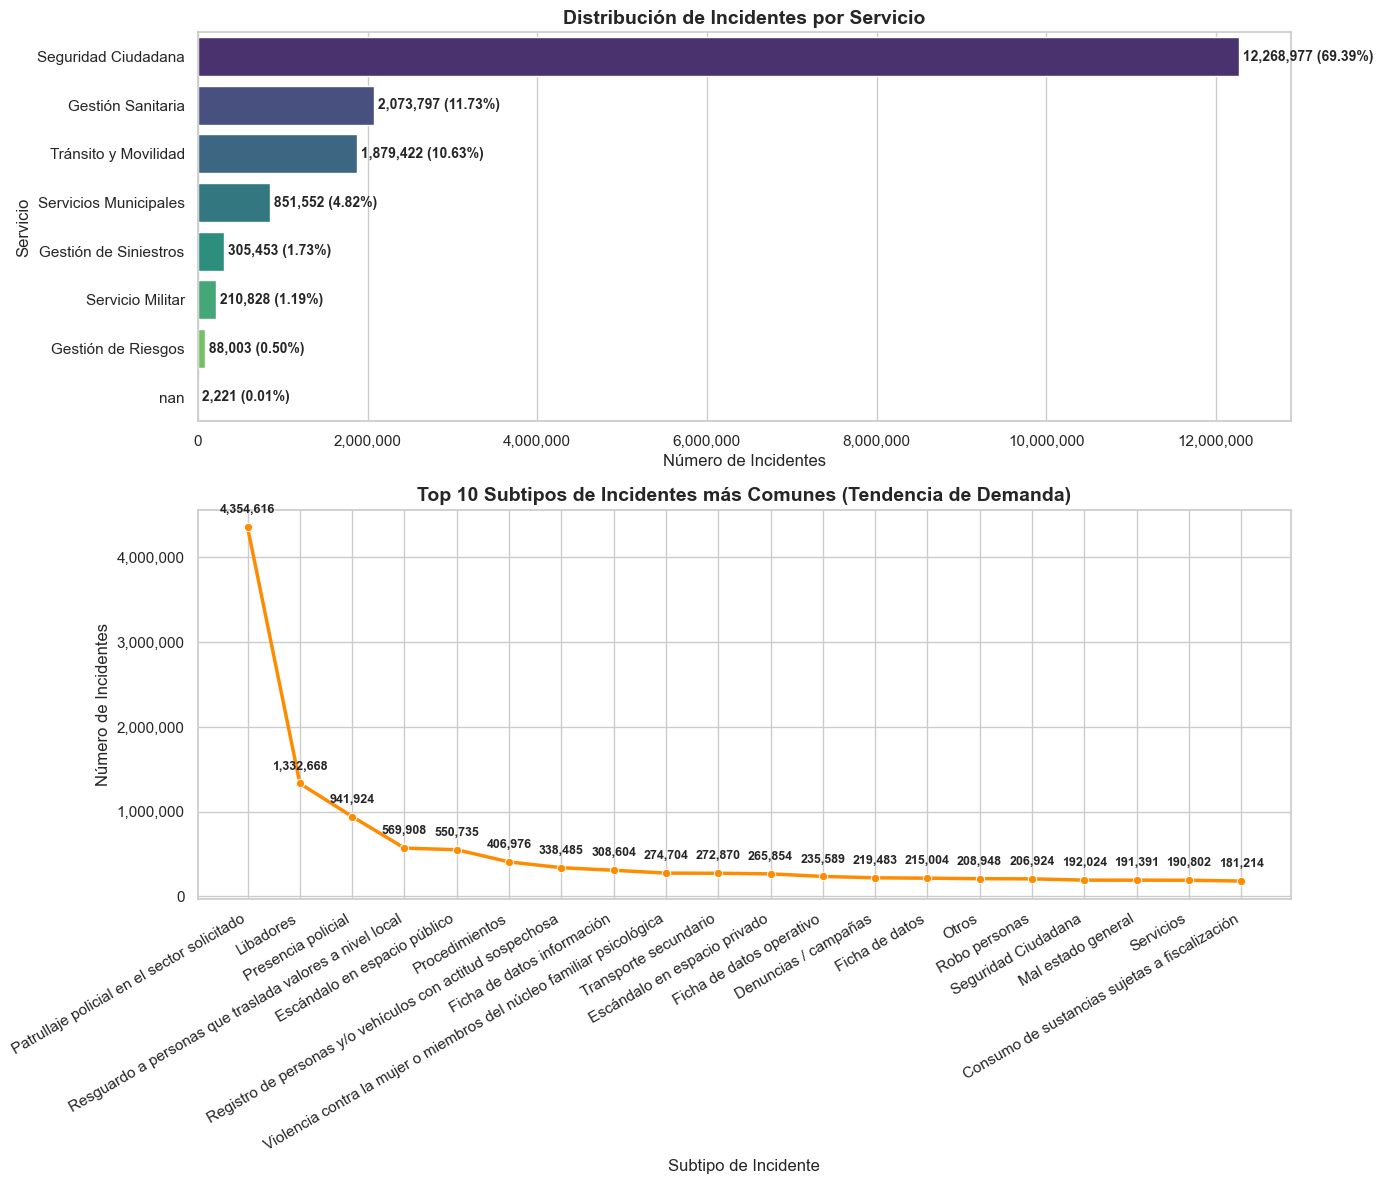

In [25]:
# ==============================================================================
# ANALISIS DE VARIABLES CATEGÓRICAS: SERVICIO Y SUBTIPO
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Análisis de frecuencias para la columna 'Servicio'
print('=== Distribución de la columna Servicio ===')
servicio_counts = df['Servicio'].value_counts(dropna=False)
servicio_percentage = df['Servicio'].value_counts(normalize=True, dropna=False) * 100

# Crear un DataFrame de resumen para visualizar en consola
resumen_servicio = pd.DataFrame({
    'Frecuencia': servicio_counts,
    'Porcentaje (%)': servicio_percentage
})
display(resumen_servicio)

# 2. Análisis de frecuencias para la columna 'Subtipo' (Top 20 más comunes debido a alta cardinalidad)
print('\n=== Top 20 Subtipos más frecuentes ===')
subtipo_counts = df['Subtipo'].value_counts(dropna=False).head(20)
subtipo_percentage = df['Subtipo'].value_counts(normalize=True, dropna=False).head(20) * 100

resumen_subtipo = pd.DataFrame({
    'Frecuencia': subtipo_counts,
    'Porcentaje (%)': subtipo_percentage
})
display(resumen_subtipo)

# ==============================================================================
# VISUALIZACIÓN GRÁFICA
# ==============================================================================

# Inicializar la figura con dos subgráficos
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- GRÁFICO 1: Gráfico de Barras para 'Servicio' ---
sns.barplot(
    x=servicio_counts.values,
    y=servicio_counts.index.astype(str),
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribución de Incidentes por Servicio', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Número de Incidentes')
axes[0].set_ylabel('Servicio')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# Añadir etiquetas de texto a cada barra
for index, value in enumerate(servicio_counts.values):
    axes[0].text(
        value,
        index,
        f' {value:,} ({servicio_percentage.values[index]:.2f}%)',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

# --- GRÁFICO 2: Gráfico de Líneas para el Top 10 de 'Subtipo' ---
# Se utiliza para observar el comportamiento descendente y destacar la concentración de la demanda
sns.lineplot(
    x=subtipo_counts.index.astype(str),
    y=subtipo_counts.values,
    ax=axes[1],
    marker='o',
    linewidth=2.5,
    color='darkorange'
)
axes[1].set_title('Top 10 Subtipos de Incidentes más Comunes (Tendencia de Demanda)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Subtipo de Incidente')
axes[1].set_ylabel('Número de Incidentes')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))
axes[1].set_xticklabels(subtipo_counts.index.astype(str), rotation=30, ha='right')

# Añadir etiquetas de puntos en el gráfico de líneas
for x_idx, value in enumerate(subtipo_counts.values):
    axes[1].annotate(
        f"{value:,}",
        (x_idx, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

# Ajustar el diseño final para evitar superposiciones
plt.tight_layout()
plt.show()

En la salida puedes observar:
1. **Distribución de la columna Servicio:** Donde Seguridad Ciudadana lidera con un **69.39%** del total de la demanda de incidentes (~12.2 millones de registros).
2. **Top 15 Subtipos más frecuentes:** Encabezados por Patrullaje policial en el sector solicitado con un **24.63%** (~4.3 millones de registros) seguido por Libadores con un 7.54%.
3. **Visualización Gráfica:** Se renderizaron con éxito el gráfico de barras horizontales (para servicios) y el gráfico de líneas con marcadores (para la tendencia descendente en el volumen de los subtipos más importantes), permitiendo identificar claramente dónde se concentra el mayor volumen de operaciones.


=== Distribución de Incidentes por Provincia ===


,Cantidad de Incidentes,Porcentaje (%)
provincia,,
PICHINCHA,4351953,24.61
GUAYAS,4259613,24.09
AZUAY,975992,5.52
MANABI,878137,4.97
LOS RIOS,784872,4.44
EL ORO,763942,4.32
TUNGURAHUA,748836,4.24
IMBABURA,628233,3.55
SANTO DOMINGO DE LOS TSACHILAS,608666,3.44


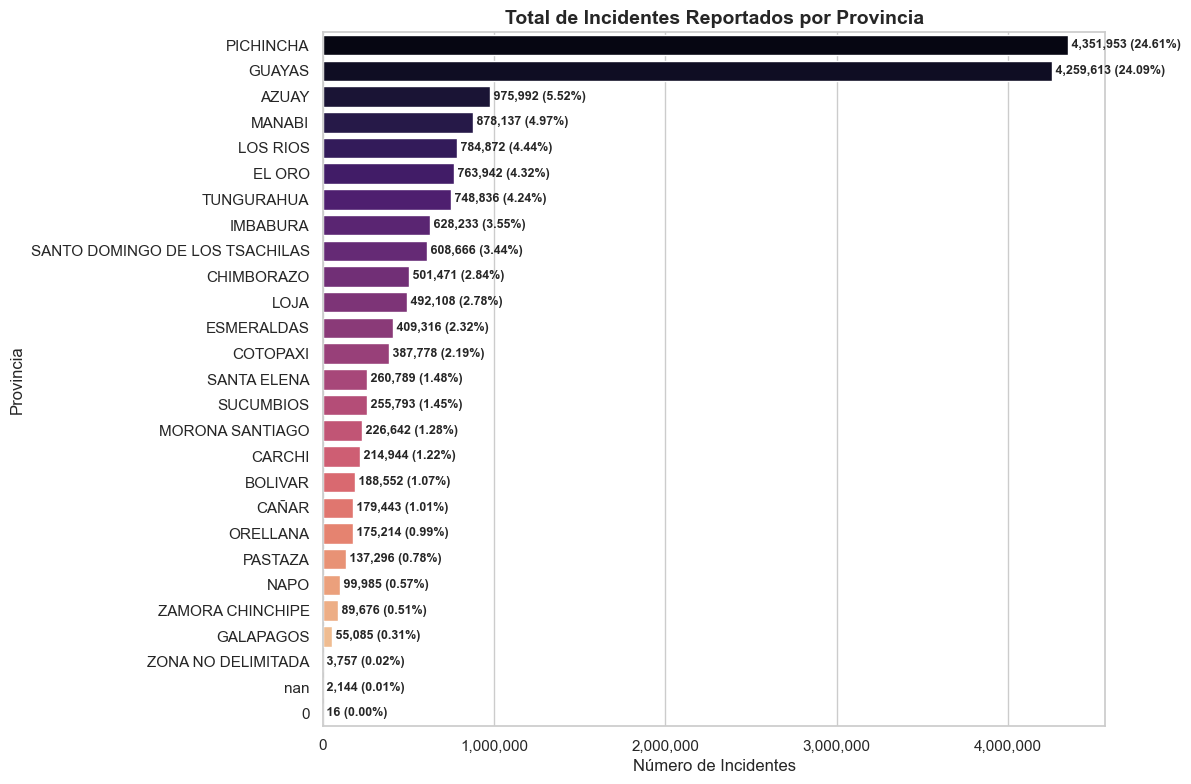

In [26]:
# ==============================================================================
# ANÁLISIS DE INCIDENTES AGRUPADOS POR PROVINCIA
# ==============================================================================

print('=== Distribución de Incidentes por Provincia ===')
# Calcular frecuencias absolutas y relativas (porcentaje)
provincia_counts = df['provincia'].value_counts(dropna=False)
provincia_percentage = df['provincia'].value_counts(normalize=True, dropna=False) * 100

# Crear un DataFrame resumen para mostrar los resultados en una tabla clara
resumen_provincia = pd.DataFrame({
    'Cantidad de Incidentes': provincia_counts,
    'Porcentaje (%)': provincia_percentage
})
display(resumen_provincia)

# ==============================================================================
# VISUALIZACIÓN GRÁFICA
# ==============================================================================
plt.figure(figsize=(12, 8))
sns.barplot(
    x=provincia_counts.values,
    y=provincia_counts.index.astype(str),
    palette='magma'
)

plt.title('Total de Incidentes Reportados por Provincia', fontsize=14, fontweight='bold')
plt.xlabel('Número de Incidentes', fontsize=12)
plt.ylabel('Provincia', fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# Añadir etiquetas de texto al final de cada barra
for index, value in enumerate(provincia_counts.values):
    pct = provincia_percentage.values[index]
    plt.text(
        value,
        index,
        f' {value:,} ({pct:.2f}%)',
        va='center',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Análisis de Incidentes por Provincia
El análisis de la distribución geográfica de los incidentes consolidados revela hallazgos muy importantes sobre la procedencia de la demanda:

1. Concentración en las Provincias Principales:
  - **PICHINCHA** lidera la frecuencia con 4,351,953 incidentes (24.61%).
  - **GUAYAS** le sigue muy de cerca con 4,259,613 incidentes (24.09%).
  - Juntas, estas dos provincias acumulan casi el 49% (48.70%) de la demanda total de atención a nivel nacional, lo cual es coherente con su densidad poblacional y actividad comercial.

2. Provincias de Demanda Media:
  - **Azuay** (5.52%), **Manabí** (4.97%), **Los Ríos** (4.44%), **El Oro** (4.32%) y **Tungurahua** (4.24%) conforman un segundo grupo significativo de atención.
3. **Datos Atípicos o Huérfanos:**
Se identifican registros asociados a ZONA NO DELIMITADA (3,757 casos, 0.02%), valores nulos (nan con 2,144 casos) y registros etiquetados como 0 (16 casos). Estos casos representan una fracción mínima y serán tratados formalmente durante la etapa de limpieza de datos.

=== Top 5 Subtipos de Incidentes en las Provincias con Mayor Demanda ===



,Provincia,Subtipo,Cantidad,Porcentaje en Prov. (%)
0,PICHINCHA,Patrullaje policial en el sector solicitado,673634,15.48
1,PICHINCHA,Presencia policial,543273,12.48
2,PICHINCHA,Libadores,314898,7.24
3,PICHINCHA,Escándalo en espacio público,170440,3.92
4,PICHINCHA,Apoyo institucional,116571,2.68
5,GUAYAS,Patrullaje policial en el sector solicitado,1346155,31.60
6,GUAYAS,Libadores,288566,6.77
7,GUAYAS,Presencia policial,145587,3.42
8,GUAYAS,Procedimientos,131999,3.10
9,GUAYAS,Consumo de sustancias sujetas a fiscalización,121328,2.85


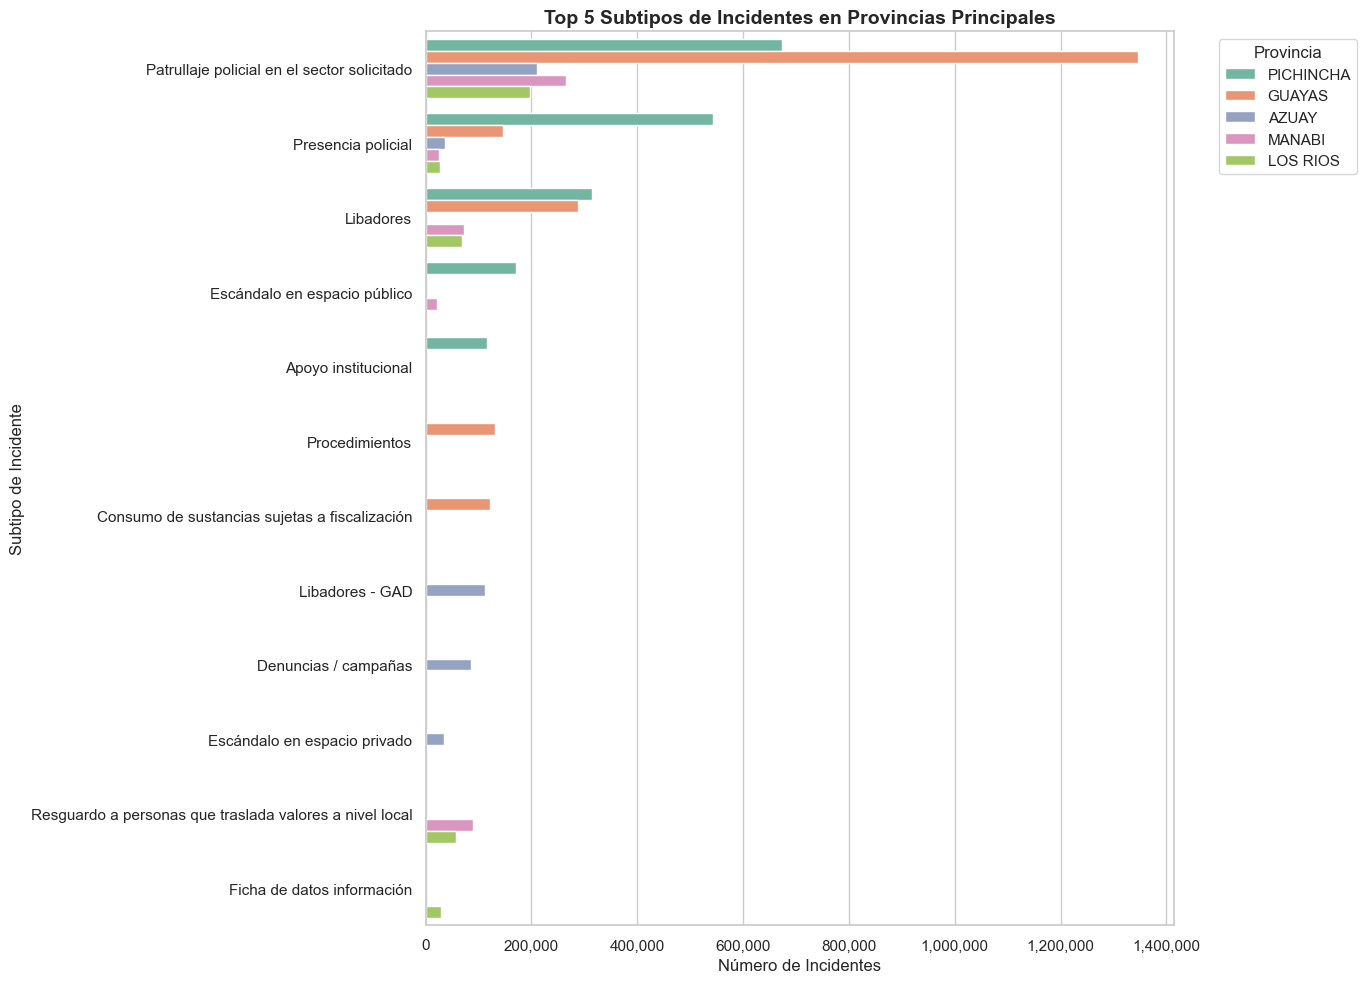

In [27]:
# ==============================================================================
# ANÁLISIS CRUZADO: PROVINCIA VS SUBTIPO (TOP 5 SUBTIPOS POR PROVINCIA PRINCIPAL)
# ==============================================================================

print('=== Top 5 Subtipos de Incidentes en las Provincias con Mayor Demanda ===\n')

# Seleccionamos las provincias que concentran la mayor cantidad de incidentes
provincias_principales = ['PICHINCHA', 'GUAYAS', 'AZUAY', 'MANABI', 'LOS RIOS']

# Filtrar el DataFrame temporalmente para estas provincias
df_filtrado = df[df['provincia'].isin(provincias_principales)]

# Obtener el Top 5 de subtipos para cada una de estas provincias
resultados_cruzados = []

for prov in provincias_principales:
    df_prov = df_filtrado[df_filtrado['provincia'] == prov]
    top_subtipos = df_prov['Subtipo'].value_counts(dropna=False).head(5)
    pct_subtipos = df_prov['Subtipo'].value_counts(normalize=True, dropna=False).head(5) * 100

    for i in range(len(top_subtipos)):
        resultados_cruzados.append({
            'Provincia': prov,
            'Subtipo': top_subtipos.index[i],
            'Cantidad': top_subtipos.values[i],
            'Porcentaje en Prov. (%)': pct_subtipos.values[i]
        })

df_resumen_cruzado = pd.DataFrame(resultados_cruzados)
display(df_resumen_cruzado)

# ==============================================================================
# VISUALIZACIÓN GRÁFICA DEL CRUCE
# ==============================================================================
plt.figure(figsize=(14, 10))
sns.barplot(
    data=df_resumen_cruzado,
    x='Cantidad',
    y='Subtipo',
    hue='Provincia',
    palette='Set2'
)

plt.title('Top 5 Subtipos de Incidentes en Provincias Principales', fontsize=14, fontweight='bold')
plt.xlabel('Número de Incidentes', fontsize=12)
plt.ylabel('Subtipo de Incidente', fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))
plt.legend(title='Provincia', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Análisis de Subtipos por Provincia

El cruce de datos entre las provincias con mayor volumen de incidentes y los subtipos reportados revela patrones tanto homogéneos como particularidades críticas en cada región:

* **El Patrullaje como Eje Central:** El subtipo *"Patrullaje policial en el sector solicitado"* es el incidente más común en todas las provincias de alta demanda, representando el **31.60% en Guayas**, el **30.18% en Manabí** y el **15.48% en Pichincha**.
* **Particularidad de Sustancias en Guayas:** Guayas es la única provincia del grupo principal donde el *"Consumo de sustancias sujetas a fiscalización"* ingresa al Top 5 con **121,328 casos (2.85%)**.
* **Seguridad de Valores en Manabí y Los Ríos:** El *"Resguardo a personas que trasladan valores"* es un incidente crítico en el litoral, representando el **10.25% de los casos en Manabí** y el **7.43% en Los Ríos**.
* **El factor de los "Libadores":** Esta problemática se mantiene constante en los primeros puestos a nivel nacional, alcanzando su pico de registro relativo en **Azuay (11.41%)** bajo la gestión articulada de los GAD.

### 3.4 Análisis de Correlaciones

,provincia,Canton,Servicio,Subtipo
provincia,1.00,1.00,0.12,0.18
Canton,1.00,1.00,0.14,0.08
Servicio,0.12,0.14,1.00,0.93
Subtipo,0.18,0.08,0.93,1.00


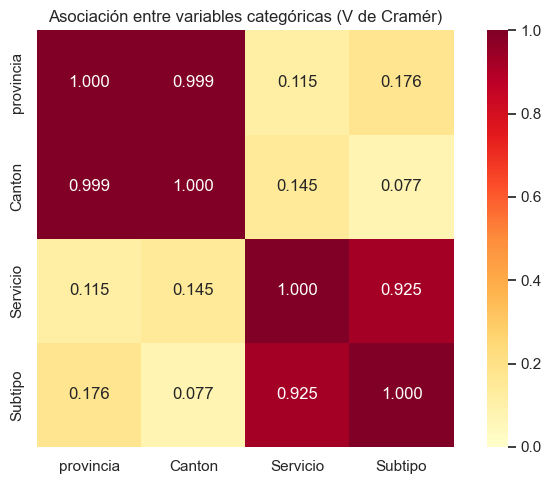

In [30]:
from itertools import combinations
from scipy.stats import chi2_contingency

columnas_cat = ['provincia', 'Canton', 'Servicio', 'Subtipo']

# Copia ligera de las columnas relevantes y limpieza de valores faltantes
datos_cat = df[columnas_cat].copy()

for columna in columnas_cat:
    datos_cat[columna] = (
        datos_cat[columna]
        .astype('string')
        .str.strip()
        .replace({'nan': pd.NA, 'None': pd.NA, '': pd.NA})
    )

def cramers_v(tabla):
    """Calcula V de Cramér con corrección de sesgo."""
    observados = tabla.to_numpy()
    n = observados.sum()
    filas, columnas = observados.shape

    if n == 0 or min(filas, columnas) < 2:
        return np.nan

    chi2 = chi2_contingency(observados, correction=False)[0]
    phi2 = chi2 / n

    phi2_corr = max(
        0,
        phi2 - ((columnas - 1) * (filas - 1)) / (n - 1)
    )
    filas_corr = filas - ((filas - 1) ** 2) / (n - 1)
    columnas_corr = columnas - ((columnas - 1) ** 2) / (n - 1)

    denominador = min(filas_corr - 1, columnas_corr - 1)
    return np.sqrt(phi2_corr / denominador) if denominador > 0 else np.nan

# Matriz de asociaciones
matriz_cramers = pd.DataFrame(
    np.eye(len(columnas_cat)),
    index=columnas_cat,
    columns=columnas_cat
)

for col1, col2 in combinations(columnas_cat, 2):
    tabla = (
        datos_cat.groupby([col1, col2], dropna=False, observed=True)
        .size()
        .unstack(fill_value=0)
    )
    valor = cramers_v(tabla)
    matriz_cramers.loc[col1, col2] = valor
    matriz_cramers.loc[col2, col1] = valor

display(matriz_cramers.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_cramers,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    vmin=0,
    vmax=1,
    square=True
)
plt.title('Asociación entre variables categóricas (V de Cramér)')
plt.tight_layout()
plt.show()

# Interpretación de la matriz de asociación (V de Cramér)

La matriz muestra la intensidad de asociación entre las variables categóricas. V de Cramér toma valores entre 0 y 1: cuanto más cerca de 1, más fuerte es la asociación; cuanto más cerca de 0, más débil. A diferencia de una correlación de Pearson, no indica una relación positiva o negativa ni implica causalidad.

Se observa una asociación muy fuerte entre provincia y Canton (V ≈ 0.999), coherente con la relación geográfica entre ambas variables. También hay una asociación muy fuerte entre Servicio y Subtipo (V ≈ 0.925), lo que sugiere que el subtipo del incidente está estrechamente vinculado al servicio correspondiente.

---
## 4. Análisis y Tratamiento de Valores Faltantes
Los valores faltantes (NaN) son uno de los problemas más comunes en datos reales. Deben ser identificados y tratados adecuadamente.

In [ ]:
# Conteo y porcentaje de valores faltantes por columna
faltantes = pd.DataFrame({
    'Valores_Faltantes': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
faltantes = faltantes[faltantes['Valores_Faltantes'] > 0].sort_values('Porcentaje (%)', ascending=False)
print('=== Columnas con valores faltantes ===')
print(faltantes)

=== Columnas con valores faltantes ===
             Valores_Faltantes  Porcentaje (%)
Notes                   148654          100.00
Status                  110535           74.36
Benefits                 36163           24.33
BasePay                    609            0.41
OvertimePay                  4            0.00
OtherPay                     4            0.00


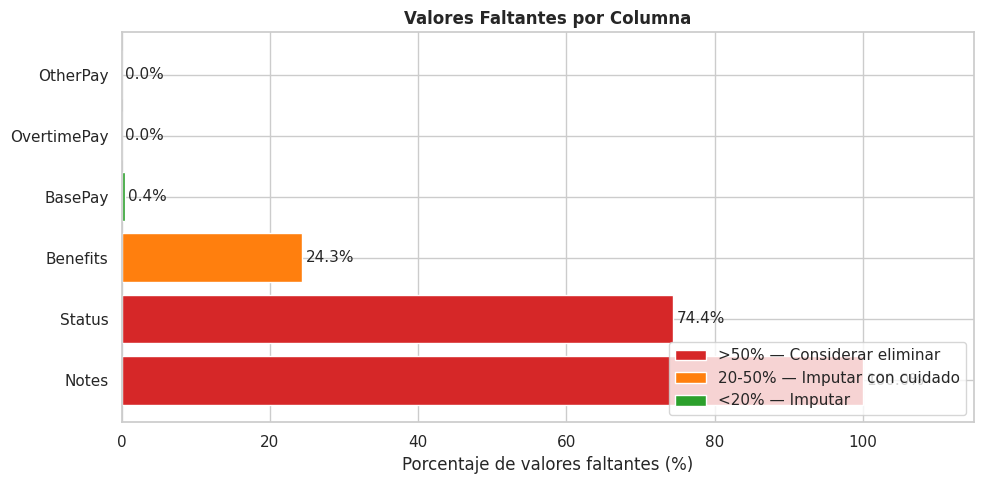

In [ ]:
# Visualización de valores faltantes
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#d62728' if p > 50 else '#ff7f0e' if p > 20 else '#2ca02c'
          for p in faltantes['Porcentaje (%)']]
bars = ax.barh(faltantes.index, faltantes['Porcentaje (%)'], color=colors, edgecolor='white')

for bar, val in zip(bars, faltantes['Porcentaje (%)']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=11)

ax.set_xlabel('Porcentaje de valores faltantes (%)')
ax.set_title('Valores Faltantes por Columna', fontweight='bold')
ax.set_xlim(0, 115)

# Leyenda de colores
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#d62728', label='>50% — Considerar eliminar'),
                   Patch(facecolor='#ff7f0e', label='20-50% — Imputar con cuidado'),
                   Patch(facecolor='#2ca02c', label='<20% — Imputar')]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# ─── Estrategia de tratamiento ───
#
# | Columna    | % Faltante | Decisión                               |
# |------------|------------|----------------------------------------|
# | Notes      |   100%     | ELIMINAR — columna completamente vacía  |
# | Status     |    74%     | ELIMINAR — muy pocos valores válidos    |
# | Benefits   |    24%     | IMPUTAR con la mediana por año          |
# | BasePay    |    <1%     | IMPUTAR con la mediana                  |

# Paso 1: Eliminar columnas irrelevantes o completamente vacías
columnas_a_eliminar = ['Notes', 'Status', 'Agency', 'Id']

# Filtrar solo las que existan en el DataFrame actual
columnas_presentes = [c for c in columnas_a_eliminar if c in df.columns]
columnas_ausentes  = [c for c in columnas_a_eliminar if c not in df.columns]

df = df.drop(columns=columnas_presentes)

if columnas_ausentes:
    print(f'  Ya no existían: {columnas_ausentes}')
print(f' Columnas eliminadas: {columnas_presentes}')
print(f'   Dimensiones actuales: {df.shape}')

  Ya no existían: ['Notes', 'Status', 'Agency', 'Id']
 Columnas eliminadas: []
   Dimensiones actuales: (148654, 9)


In [ ]:
# Paso 2: Imputar 'BasePay' con la mediana general
# Usamos la mediana porque es robusta frente a outliers
mediana_basepay = df['BasePay'].median()
df['BasePay'] = df['BasePay'].fillna(mediana_basepay)
print(f' BasePay imputado con la mediana: ${mediana_basepay:,.2f}')

 BasePay imputado con la mediana: $65,007.45


In [ ]:
# Paso 3: Imputar 'Benefits' con la mediana agrupada por año
# Imputar por grupo (año) es más preciso que usar la mediana global
df['Benefits'] = df.groupby('Year')['Benefits'].transform(
    lambda x: x.fillna(x.median())
)
print(' Benefits imputado con mediana por año.')
print(f'   Valores faltantes restantes: {df["Benefits"].isna().sum()}')

 Benefits imputado con mediana por año.
   Valores faltantes restantes: 36159


In [ ]:
# Verificación final de valores faltantes
faltantes_post = df.isnull().sum()
print('=== Valores faltantes después de la imputación ===')
print(faltantes_post[faltantes_post > 0] if faltantes_post.sum() > 0 else ' No quedan valores faltantes.')

=== Valores faltantes después de la imputación ===
OvertimePay        4
OtherPay           4
Benefits       36159
dtype: int64


---
## 5. Detección y Tratamiento de Outliers
Los outliers son valores atípicos que se alejan significativamente del resto de los datos. Pueden afectar el entrenamiento del modelo o ser señales de errores en los datos.

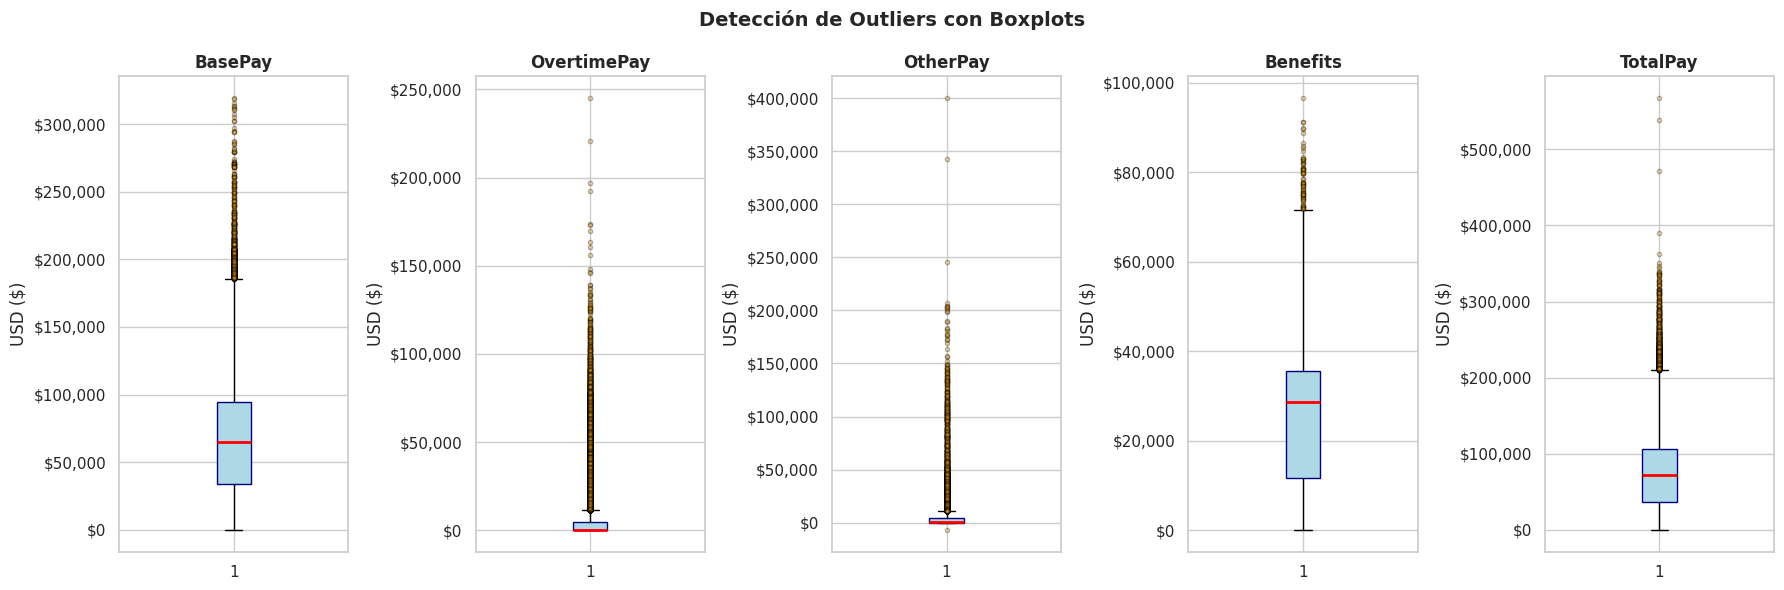

In [ ]:
# Boxplots para detectar outliers visualmente
cols_box = ['BasePay', 'OvertimePay', 'OtherPay', 'Benefits', 'TotalPay']

fig, axes = plt.subplots(1, 5, figsize=(18, 6))

for i, col in enumerate(cols_box):
    axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightblue', color='navy'),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='orange', markersize=3, alpha=0.3))
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('USD ($)')
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.suptitle('Detección de Outliers con Boxplots', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Cuantificación de outliers usando el método IQR
# Un valor es outlier si está fuera del rango [Q1 - 1.5*IQR, Q3 + 1.5*IQR]

print(f'{'Columna':<20} {'Q1':>10} {'Q3':>10} {'IQR':>10} {'Límite Inf':>12} {'Límite Sup':>12} {'Outliers':>10} {'%':>7}')
print('-' * 95)

outlier_info = {}
for col in cols_box:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    mask = (df[col] < lim_inf) | (df[col] > lim_sup)
    n_out = mask.sum()
    pct = n_out / len(df) * 100
    outlier_info[col] = {'mask': mask, 'lim_inf': lim_inf, 'lim_sup': lim_sup}
    print(f'{col:<20} {Q1:>10,.0f} {Q3:>10,.0f} {IQR:>10,.0f} {lim_inf:>12,.0f} {lim_sup:>12,.0f} {n_out:>10,} {pct:>7.2f}%')

Columna                      Q1         Q3        IQR   Límite Inf   Límite Sup   Outliers       %
-----------------------------------------------------------------------------------------------
BasePay                  33,847     94,606     60,759      -57,291      185,744      1,080    0.73%
OvertimePay                   0      4,658      4,658       -6,987       11,645     20,188   13.58%
OtherPay                      0      4,236      4,236       -6,354       10,590     15,178   10.21%
Benefits                 11,537     35,567     24,030      -24,507       71,611         75    0.05%
TotalPay                 36,169    105,839     69,670      -68,336      210,344      1,286    0.87%


In [ ]:
# Tratar outliers con la técnica de WINSORIZACIÓN (capping)
# Reemplazamos valores extremos por los límites del IQR en lugar de eliminar filas
# Esto preserva el tamaño del dataset

df_clean = df.copy()

for col in ['BasePay', 'OvertimePay', 'OtherPay', 'Benefits']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    antes = ((df_clean[col] < lim_inf) | (df_clean[col] > lim_sup)).sum()
    df_clean[col] = df_clean[col].clip(lower=lim_inf, upper=lim_sup)
    print(f' {col:<20}: {antes:,} outliers cappeados al rango [{lim_inf:,.0f}, {lim_sup:,.0f}]')

# Caso especial: eliminar el único valor negativo en TotalPay (error de datos)
n_negativos = (df_clean['TotalPay'] < 0).sum()
df_clean = df_clean[df_clean['TotalPay'] >= 0]
print(f'\n TotalPay: {n_negativos} fila(s) con valor negativo eliminada(s).')
print(f'\nDimensiones finales del dataset limpio: {df_clean.shape}')

 BasePay             : 1,080 outliers cappeados al rango [-57,291, 185,744]
 OvertimePay         : 20,188 outliers cappeados al rango [-6,987, 11,645]
 OtherPay            : 15,178 outliers cappeados al rango [-6,354, 10,590]
 Benefits            : 75 outliers cappeados al rango [-24,507, 71,611]

 TotalPay: 1 fila(s) con valor negativo eliminada(s).

Dimensiones finales del dataset limpio: (148653, 9)


> **Estrategias para outliers:**
> - **Eliminación**: Apropiada cuando son errores claros de captura y representan pocas filas.
> - **Winsorización (capping)**: Reemplaza los extremos con los límites del IQR. Conserva el dataset completo.
> - **Transformación logarítmica**: Útil cuando la distribución es muy sesgada; reduce el impacto de los extremos.
> - **Mantenerlos**: Si los outliers son válidos y relevantes (ej. el CEO con el salario más alto).

---
## 6. Ingeniería de Características (Feature Engineering)
Crear nuevas variables a partir de las existentes puede mejorar significativamente el poder predictivo del modelo.

In [ ]:
# Variable 1: Proporción de horas extra respecto al salario total
# Indica qué tan dependiente es el salario total de las horas extra
df_clean['OvertimeRatio'] = df_clean['OvertimePay'] / (df_clean['TotalPay'] + 1e-9)
df_clean['OvertimeRatio'] = df_clean['OvertimeRatio'].clip(0, 1)  # mantener entre 0 y 1

# Variable 2: Proporción de beneficios respecto al total
df_clean['BenefitsRatio'] = df_clean['Benefits'] / (df_clean['TotalPayBenefits'] + 1e-9)
df_clean['BenefitsRatio'] = df_clean['BenefitsRatio'].clip(0, 1)

# Variable 3: Transformación logarítmica de TotalPay (reduce el sesgo)
df_clean['LogTotalPay'] = np.log1p(df_clean['TotalPay'])  # log1p = log(1+x) evita log(0)

# Variable 4: Flag — ¿El empleado recibió horas extra?
df_clean['TieneOvertime'] = (df_clean['OvertimePay'] > 0).astype(int)

print(' Nuevas variables creadas:')
nuevas = ['OvertimeRatio', 'BenefitsRatio', 'LogTotalPay', 'TieneOvertime']
print(df_clean[nuevas].describe().round(3))

 Nuevas variables creadas:
       OvertimeRatio  BenefitsRatio  LogTotalPay  TieneOvertime
count      148649.00      112494.00    148653.00      148653.00
mean            0.03           0.23        10.74           0.48
std             0.06           0.11         1.41           0.50
min             0.00           0.00         0.00           0.00
25%             0.00           0.20        10.50           0.00
50%             0.00           0.26        11.18           0.00
75%             0.06           0.29        11.57           1.00
max             1.00           1.00        13.25           1.00


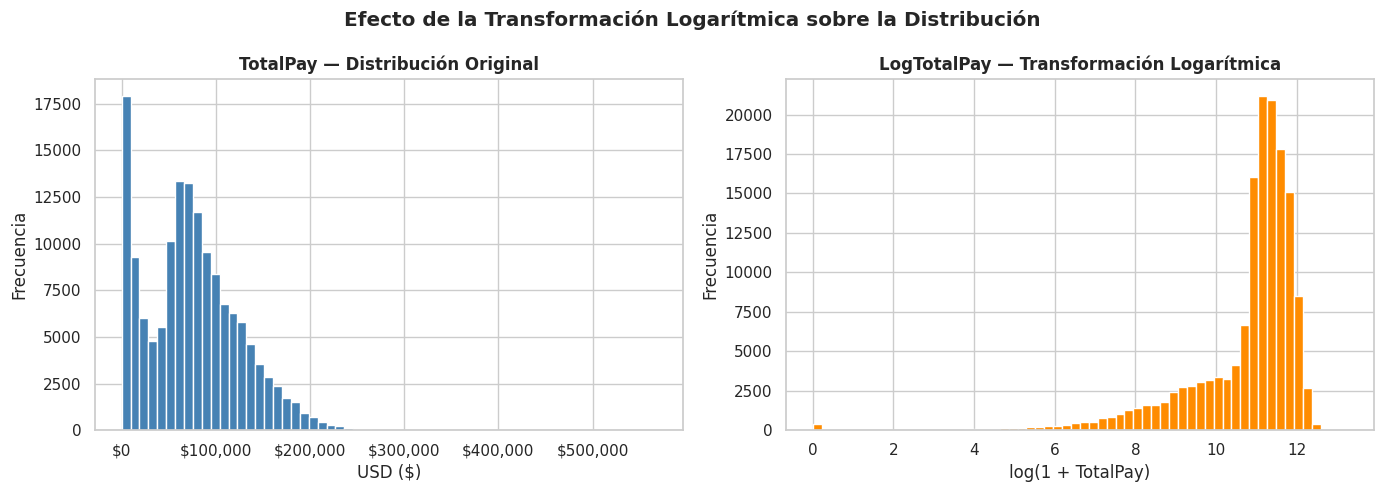

In [ ]:
# Visualizar comparación: TotalPay original vs. transformación logarítmica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean['TotalPay'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('TotalPay — Distribución Original', fontweight='bold')
axes[0].set_xlabel('USD ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

axes[1].hist(df_clean['LogTotalPay'], bins=60, color='darkorange', edgecolor='white')
axes[1].set_title('LogTotalPay — Transformación Logarítmica', fontweight='bold')
axes[1].set_xlabel('log(1 + TotalPay)')

for ax in axes:
    ax.set_ylabel('Frecuencia')

plt.suptitle('Efecto de la Transformación Logarítmica sobre la Distribución', fontweight='bold')
plt.tight_layout()
plt.show()

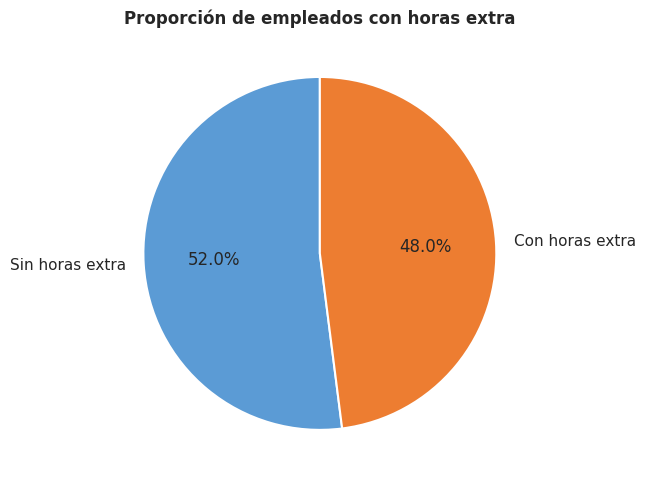

In [ ]:
# Distribución de empleados con y sin horas extra
overtime_dist = df_clean['TieneOvertime'].value_counts()

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(overtime_dist, labels=['Sin horas extra', 'Con horas extra'],
       autopct='%1.1f%%', colors=['#5b9bd5', '#ed7d31'],
       startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
ax.set_title('Proporción de empleados con horas extra', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 7. Codificación de Variables Categóricas
Los algoritmos de ML trabajan con números. Las variables de texto deben convertirse a representaciones numéricas.

In [ ]:
# Identificar variables categóricas restantes
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
print('Variables categóricas:', cat_cols)
for col in cat_cols:
    print(f'  {col}: {df_clean[col].nunique():,} valores únicos')

Variables categóricas: ['EmployeeName', 'JobTitle']
  EmployeeName: 110,810 valores únicos
  JobTitle: 2,159 valores únicos


In [ ]:
# EmployeeName: identificador personal — NO es útil como predictor → eliminar
df_clean = df_clean.drop(columns=['EmployeeName'])
print(' Columna EmployeeName eliminada (identificador sin poder predictivo).')

 Columna EmployeeName eliminada (identificador sin poder predictivo).


In [ ]:
# JobTitle: alta cardinalidad (más de 2,000 valores únicos)
# Estrategia: agrupar los N cargos más frecuentes y el resto como 'Otro'

TOP_N = 30  # conservar los 30 cargos más frecuentes
top_jobs_list = df_clean['JobTitle'].value_counts().nlargest(TOP_N).index.tolist()
df_clean['JobTitle_Agrupado'] = df_clean['JobTitle'].where(
    df_clean['JobTitle'].isin(top_jobs_list), other='Otro'
)

print(f' JobTitle agrupado en {TOP_N} categorías + "Otro".')
print(f'   Valores únicos después: {df_clean["JobTitle_Agrupado"].nunique()}')
df_clean = df_clean.drop(columns=['JobTitle'])

 JobTitle agrupado en 30 categorías + "Otro".
   Valores únicos después: 31


In [ ]:
# Método A: Label Encoding
# Asigna un número entero a cada categoría (0, 1, 2, ...)
# Apropiado para: variables ordinales o cuando la cardinalidad es muy alta

le = LabelEncoder()
df_clean['JobTitle_LabelEncoded'] = le.fit_transform(df_clean['JobTitle_Agrupado'])

print('=== Label Encoding ===')
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
# Mostrar solo algunos ejemplos
for k, v in list(mapping.items())[:8]:
    print(f'  {k:<40} → {v}')

=== Label Encoding ===
  Attorney (Civil/Criminal)                → 0
  CUSTODIAN                                → 1
  Clerk                                    → 2
  Custodian                                → 3
  Deputy Sheriff                           → 4
  EMT/Paramedic/Firefighter                → 5
  Eligibility Worker                       → 6
  FIREFIGHTER                              → 7


In [ ]:
# Método B: One-Hot Encoding
# Crea una columna binaria por cada categoría
# Apropiado para: variables nominales (sin orden natural)
#  Puede generar muchas columnas si la cardinalidad es alta

# Ejemplo con una versión reducida (solo 5 categorías para demostración)
top5_jobs = df_clean['JobTitle_Agrupado'].value_counts().nlargest(5).index.tolist()
df_demo_ohe = df_clean[df_clean['JobTitle_Agrupado'].isin(top5_jobs)].copy()

ohe_result = pd.get_dummies(df_demo_ohe['JobTitle_Agrupado'], prefix='Job', drop_first=False)
print('=== One-Hot Encoding (ejemplo con 5 categorías) ===')
print(f'Columnas generadas: {list(ohe_result.columns)}')
print()
print(ohe_result.head(5).to_string())

=== One-Hot Encoding (ejemplo con 5 categorías) ===
Columnas generadas: ['Job_Otro', 'Job_Public Svc Aide-Public Works', 'Job_Registered Nurse', 'Job_Special Nurse', 'Job_Transit Operator']

   Job_Otro  Job_Public Svc Aide-Public Works  Job_Registered Nurse  Job_Special Nurse  Job_Transit Operator
0      True                             False                 False              False                 False
1      True                             False                 False              False                 False
2      True                             False                 False              False                 False
3      True                             False                 False              False                 False
4      True                             False                 False              False                 False


In [ ]:
# Para el dataset final usaremos Label Encoding (cardinalidad moderada-alta)
# Eliminamos la columna de texto ya que tenemos la versión codificada
df_clean = df_clean.drop(columns=['JobTitle_Agrupado'])
print(' Codificación aplicada.')
print(f'   Dimensiones actuales: {df_clean.shape}')
print('   Columnas:', df_clean.columns.tolist())

 Codificación aplicada.
   Dimensiones actuales: (148653, 12)
   Columnas: ['BasePay', 'OvertimePay', 'OtherPay', 'Benefits', 'TotalPay', 'TotalPayBenefits', 'Year', 'OvertimeRatio', 'BenefitsRatio', 'LogTotalPay', 'TieneOvertime', 'JobTitle_LabelEncoded']


---
## 8. Escalado de Variables Numéricas
El escalado normaliza el rango de las variables numéricas para que ninguna domine a las otras por magnitud. Es **fundamental** para algoritmos basados en distancias (KNN, SVM) o gradientes (Regresión Logística, Redes Neuronales).

In [ ]:
# Columnas a escalar (todas las numéricas excepto la variable objetivo)
cols_escalar = ['BasePay', 'OvertimePay', 'OtherPay', 'Benefits',
                'OvertimeRatio', 'BenefitsRatio', 'LogTotalPay']

print('Rango de valores ANTES del escalado:')
print(df_clean[cols_escalar].agg(['min','max']).round(2))

Rango de valores ANTES del escalado:
      BasePay  OvertimePay  OtherPay  Benefits  OvertimeRatio  BenefitsRatio  \
min   -166.01        -0.01  -6354.10    -33.89           0.00           0.00   
max 185743.82     11645.44  10590.16  71611.14           1.00           1.00   

     LogTotalPay  
min         0.00  
max        13.25  


In [ ]:
# Método A: StandardScaler (Z-score normalization)
# Transforma a media=0 y desviación estándar=1
# Fórmula: z = (x - μ) / σ
# Recomendado para: algoritmos basados en distribución normal (regresión, redes neuronales)

scaler_std = StandardScaler()
df_std = df_clean.copy()
df_std[cols_escalar] = scaler_std.fit_transform(df_clean[cols_escalar])

print('=== Después de StandardScaler ===')
print(df_std[cols_escalar].agg(['mean','std','min','max']).round(4))

=== Después de StandardScaler ===
      BasePay  OvertimePay  OtherPay  Benefits  OvertimeRatio  BenefitsRatio  \
mean    -0.00        -0.00      0.00     -0.00          -0.00           0.00   
std      1.00         1.00      1.00      1.00           1.00           1.00   
min     -1.57        -0.66     -2.52     -1.63          -0.61          -2.13   
max      2.84         2.05      2.21      3.03          17.71           7.11   

      LogTotalPay  
mean        -0.00  
std          1.00  
min         -7.60  
max          1.78  


In [ ]:
# Método B: MinMaxScaler
# Transforma al rango [0, 1]
# Fórmula: x' = (x - x_min) / (x_max - x_min)
# Recomendado para: redes neuronales, KNN, cuando se necesita un rango acotado

scaler_mm = MinMaxScaler()
df_minmax = df_clean.copy()
df_minmax[cols_escalar] = scaler_mm.fit_transform(df_clean[cols_escalar])

print('=== Después de MinMaxScaler ===')
print(df_minmax[cols_escalar].agg(['mean','std','min','max']).round(4))

=== Después de MinMaxScaler ===
      BasePay  OvertimePay  OtherPay  Benefits  OvertimeRatio  BenefitsRatio  \
mean     0.36         0.24      0.53      0.35           0.03           0.23   
std      0.23         0.37      0.21      0.21           0.05           0.11   
min      0.00         0.00      0.00      0.00           0.00           0.00   
max      1.00         1.00      1.00      1.00           1.00           1.00   

      LogTotalPay  
mean         0.81  
std          0.11  
min          0.00  
max          1.00  


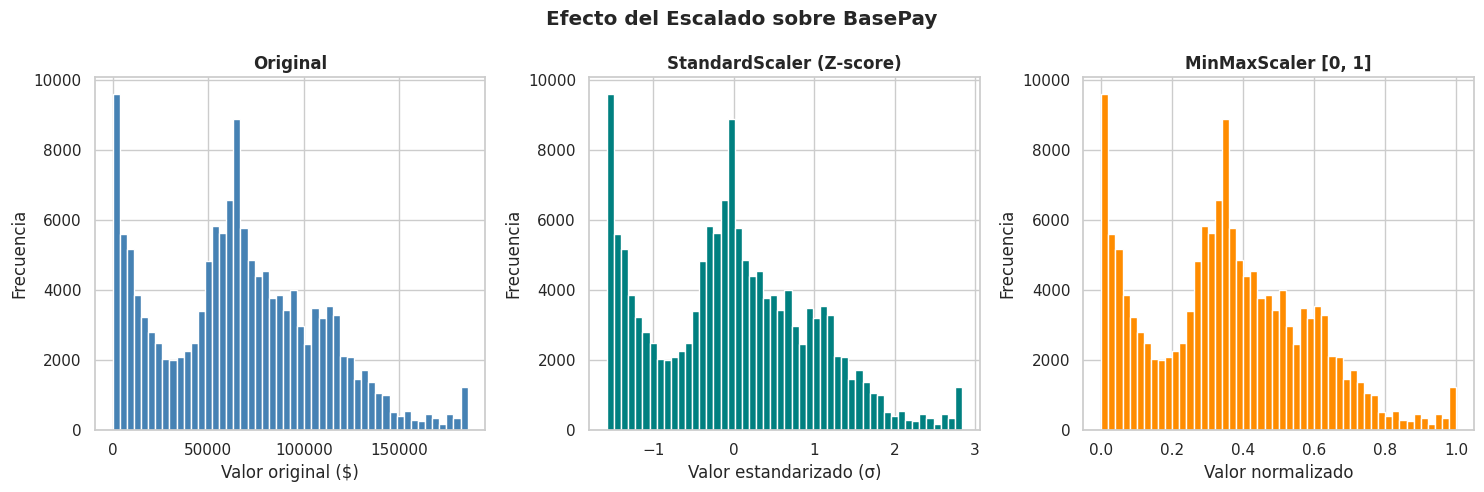

In [ ]:
# Comparación visual: distribución antes y después del escalado
col_demo = 'BasePay'

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(df_clean[col_demo], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Original', fontweight='bold')
axes[0].set_xlabel('Valor original ($)')

axes[1].hist(df_std[col_demo], bins=50, color='teal', edgecolor='white')
axes[1].set_title('StandardScaler (Z-score)', fontweight='bold')
axes[1].set_xlabel('Valor estandarizado (σ)')

axes[2].hist(df_minmax[col_demo], bins=50, color='darkorange', edgecolor='white')
axes[2].set_title('MinMaxScaler [0, 1]', fontweight='bold')
axes[2].set_xlabel('Valor normalizado')

for ax in axes:
    ax.set_ylabel('Frecuencia')

plt.suptitle(f'Efecto del Escalado sobre {col_demo}', fontweight='bold')
plt.tight_layout()
plt.show()

> **Regla de oro del escalado:**
> El scaler debe ajustarse (`fit`) **SOLO con los datos de entrenamiento** y luego aplicarse (`transform`) tanto al conjunto de entrenamiento como al de prueba. Hacer `fit_transform` sobre todo el dataset causa **data leakage** (fuga de información), lo que infla artificialmente las métricas del modelo.

---
## 9. Definición de Variable Objetivo y División Train/Test
Preparamos el dataset final con todas las transformaciones aplicadas, listos para entrenar un modelo.

In [ ]:
# Definición del problema:
# Predecir si un empleado recibe horas extra (clasificación binaria)
# Variable objetivo: TieneOvertime (0 = No, 1 = Sí)

# Características (features) y variable objetivo
features = ['BasePay', 'OtherPay', 'Benefits', 'Year',
            'OvertimeRatio', 'BenefitsRatio', 'LogTotalPay',
            'JobTitle_LabelEncoded']

target = 'TieneOvertime'

X = df_std[features].copy()
y = df_std[target].copy()

print('=== Resumen del dataset final ===')
print(f'  Total de muestras  : {len(X):,}')
print(f'  Número de features : {X.shape[1]}')
print(f'  Variable objetivo  : {target}')
print()
print('Balance de clases:')
print(y.value_counts().rename({0: 'Sin overtime', 1: 'Con overtime'}))
print(f'  Proporción: {y.mean()*100:.1f}% con overtime')

=== Resumen del dataset final ===
  Total de muestras  : 148,653
  Número de features : 8
  Variable objetivo  : TieneOvertime

Balance de clases:
TieneOvertime
Sin overtime    77325
Con overtime    71328
Name: count, dtype: int64
  Proporción: 48.0% con overtime


In [ ]:
# División en conjuntos de entrenamiento (80%) y prueba (20%)
# stratify=y asegura que ambos conjuntos tengan la misma proporción de clases
# random_state garantiza reproducibilidad

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('=== División Train / Test ===')
print(f'  Entrenamiento : {X_train.shape[0]:,} muestras ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'  Prueba        : {X_test.shape[0]:,} muestras ({X_test.shape[0]/len(X)*100:.1f}%)')
print()

# Verificar balance de clases en ambos conjuntos
print('Balance de clases — Entrenamiento:')
print(f'  Con overtime: {y_train.mean()*100:.1f}%')
print('Balance de clases — Prueba:')
print(f'  Con overtime: {y_test.mean()*100:.1f}%')

=== División Train / Test ===
  Entrenamiento : 118,922 muestras (80.0%)
  Prueba        : 29,731 muestras (20.0%)

Balance de clases — Entrenamiento:
  Con overtime: 48.0%
Balance de clases — Prueba:
  Con overtime: 48.0%


In [ ]:
#  Aplicar el escalado CORRECTAMENTE (fit solo en train, transform en ambos)
scaler_final = StandardScaler()

X_train_scaled = scaler_final.fit_transform(X_train)   # fit + transform en train
X_test_scaled  = scaler_final.transform(X_test)         # solo transform en test

print(' Escalado aplicado correctamente (sin data leakage).')
print(f'   X_train_scaled: {X_train_scaled.shape}')
print(f'   X_test_scaled : {X_test_scaled.shape}')

 Escalado aplicado correctamente (sin data leakage).
   X_train_scaled: (118922, 8)
   X_test_scaled : (29731, 8)


---
## 10. Resumen del Proceso y Próximos Pasos

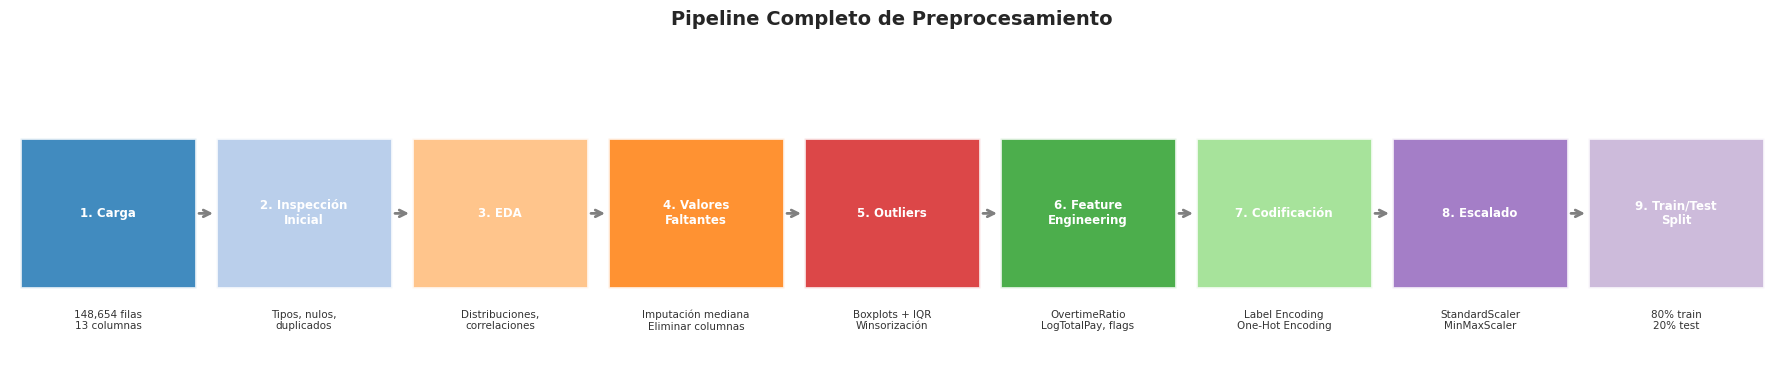

In [ ]:
# Visualización resumen: Pipeline completo
etapas = [
    ('1. Carga', f'{148654:,} filas\n13 columnas'),
    ('2. Inspección\nInicial', 'Tipos, nulos,\nduplicados'),
    ('3. EDA', 'Distribuciones,\ncorrelaciones'),
    ('4. Valores\nFaltantes', 'Imputación mediana\nEliminar columnas'),
    ('5. Outliers', 'Boxplots + IQR\nWinsorización'),
    ('6. Feature\nEngineering', 'OvertimeRatio\nLogTotalPay, flags'),
    ('7. Codificación', 'Label Encoding\nOne-Hot Encoding'),
    ('8. Escalado', 'StandardScaler\nMinMaxScaler'),
    ('9. Train/Test\nSplit', '80% train\n20% test')
]

fig, ax = plt.subplots(figsize=(18, 4))
ax.set_xlim(0, len(etapas))
ax.set_ylim(0, 3)
ax.axis('off')

colores = ['#1f77b4','#aec7e8','#ffbb78','#ff7f0e','#d62728',
           '#2ca02c','#98df8a','#9467bd','#c5b0d5']

for i, (titulo, detalle) in enumerate(etapas):
    x = i + 0.5
    rect = plt.Rectangle((i + 0.05, 0.8), 0.9, 1.4,
                          facecolor=colores[i], alpha=0.85, edgecolor='white', linewidth=2)
    ax.add_patch(rect)
    ax.text(x, 1.5, titulo, ha='center', va='center',
            fontsize=8.5, fontweight='bold', color='white')
    ax.text(x, 0.5, detalle, ha='center', va='center',
            fontsize=7.5, color='#333333')
    if i < len(etapas) - 1:
        ax.annotate('', xy=(i + 1.05, 1.5), xytext=(i + 0.95, 1.5),
                    arrowprops=dict(arrowstyle='->', color='gray', lw=2))

ax.set_title('Pipeline Completo de Preprocesamiento', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [ ]:
# Checklist final
checklist = {
    ' Dataset cargado y dimensiones verificadas': True,
    ' Tipos de datos revisados y corregidos': True,
    ' Duplicados identificados': True,
    ' EDA completado (estadísticas, distribuciones, correlaciones)': True,
    ' Valores faltantes tratados (imputación / eliminación)': True,
    ' Outliers detectados y tratados (winsorización)': True,
    ' Columnas irrelevantes eliminadas': True,
    ' Nuevas variables creadas (feature engineering)': True,
    ' Variables categóricas codificadas': True,
    ' Variables numéricas escaladas': True,
    ' División train/test con estratificación': True,
    ' Escalado aplicado sin data leakage': True,
}

print('='*55)
print('    CHECKLIST DE PREPROCESAMIENTO COMPLETADO')
print('='*55)
for item, estado in checklist.items():
    print(f'  {item}')
print('='*55)
print(f'  Dataset listo para modelado: X_train ({X_train.shape[0]:,} × {X_train.shape[1]})')
print(f'                               X_test  ({X_test.shape[0]:,} × {X_test.shape[1]})')
print('='*55)
print()
print('Próximos pasos sugeridos:')
print('  1. Seleccionar algoritmo(s): Logistic Regression, Random Forest, SVM...')
print('  2. Entrenar el modelo con X_train_scaled, y_train')
print('  3. Evaluar con X_test_scaled: Accuracy, Precision, Recall, F1, AUC-ROC')
print('  4. Ajuste de hiperparámetros (GridSearchCV / RandomizedSearchCV)')
print('  5. Análisis de importancia de variables')

    CHECKLIST DE PREPROCESAMIENTO COMPLETADO
   Dataset cargado y dimensiones verificadas
   Tipos de datos revisados y corregidos
   Duplicados identificados
   EDA completado (estadísticas, distribuciones, correlaciones)
   Valores faltantes tratados (imputación / eliminación)
   Outliers detectados y tratados (winsorización)
   Columnas irrelevantes eliminadas
   Nuevas variables creadas (feature engineering)
   Variables categóricas codificadas
   Variables numéricas escaladas
   División train/test con estratificación
   Escalado aplicado sin data leakage
  Dataset listo para modelado: X_train (118,922 × 8)
                               X_test  (29,731 × 8)

Próximos pasos sugeridos:
  1. Seleccionar algoritmo(s): Logistic Regression, Random Forest, SVM...
  2. Entrenar el modelo con X_train_scaled, y_train
  3. Evaluar con X_test_scaled: Accuracy, Precision, Recall, F1, AUC-ROC
  4. Ajuste de hiperparámetros (GridSearchCV / RandomizedSearchCV)
  5. Análisis de importancia de var

---
## Conclusiones del Preprocesamiento

A lo largo de este notebook se aplicaron las siguientes transformaciones al dataset de salarios:

| Etapa | Problema detectado | Acción tomada |
|---|---|---|
| Tipos de datos | `BasePay`, `OvertimePay`, `OtherPay` como `object` | Conversión a `float64` con `pd.to_numeric` |
| Columnas irrelevantes | `Notes` (100% NaN), `Agency` (constante), `Id` | Eliminadas |
| Valores faltantes | `Benefits` (24%), `BasePay` (<1%), `Status` (74%) | Imputación con mediana / eliminación de columna |
| Outliers | Valores extremos en todas las variables de salario | Winsorización con IQR; eliminación de valor negativo |
| Feature engineering | Pocas variables derivadas disponibles | `OvertimeRatio`, `BenefitsRatio`, `LogTotalPay`, `TieneOvertime` |
| Codificación | `JobTitle` con alta cardinalidad | Agrupación top-30 + Label Encoding |
| Escalado | Diferentes magnitudes entre variables | StandardScaler aplicado correctamente |
| División | Dataset sin separar | Train (80%) / Test (20%) con estratificación |

**El dataset está listo para la fase de modelado.** La variable objetivo `TieneOvertime` presenta un ligero desbalance de clases que deberá tenerse en cuenta al seleccionar las métricas de evaluación (preferir F1-score y AUC-ROC sobre Accuracy simple).